In [ ]:
from langgraph.graph import StateGraph, START, END
from langchain_groq import ChatGroq
from typing import TypedDict, Annotated, Literal
from pydantic import BaseModel, Field
from dotenv import load_dotenv
import operator

load_dotenv()

True

In [ ]:
model = ChatGroq(model="openai/gpt-oss-20b")

In [ ]:
class SentimentSchema(BaseModel):

    sentiment: Literal["positive","negative"] = Field(description='Sentiment of the Review')

In [ ]:
class DiagnosisSchema(BaseModel):
    issue_type: Literal["UX", "Performance", "Bug", "Support", "Other"] = Field(description='The category of issue mentioned in the review')
    tone: Literal["angry", "frustrated", "disappointed", "calm"] = Field(description='The emotional tone expressed by the user')
    urgency: Literal["low", "medium", "high"] = Field(description='How urgent or critical the issue appears to be')

In [ ]:
sentiment_model = model.with_structured_output(SentimentSchema)
diagnosis_model = model.with_structured_output(DiagnosisSchema)

In [ ]:
class ReviewState(TypedDict):

    review: str
    sentiment: ["positive","negative"]
    diagnosis: dict
    response: str
    

In [ ]:
def Sentiment(state: ReviewState):

    prompt = f'Analyze the Review Carefully and Give a sentiment \n here the review: \n {state["review"]}'
    output = sentiment_model.invoke(prompt).sentiment

    return {'sentiment': output}

def positive_response(state: ReviewState):

    prompt = f"""Write a warm thank-you message in response to this review:
    \n\n\"{state['review']}\"\n
Also, kindly ask the user to leave feedback on our website."""
    
    response = model.invoke(prompt).content

    return {'response': response}

def run_diagnosis(state: ReviewState):

    prompt = f"""Diagnose this negative review:\n\n{state['review']}\n"
    "Return issue_type, tone, and urgency.
"""
    response = diagnosis_model.invoke(prompt)

    return {'diagnosis': response.model_dump()}

def negative_response(state: ReviewState):

    diagnosis = state['diagnosis']

    prompt = f"""You are a support assistant.
The user had a '{diagnosis['issue_type']}' issue, sounded '{diagnosis['tone']}', and marked urgency as '{diagnosis['urgency']}'.
Write an empathetic, helpful resolution message.
"""
    response = model.invoke(prompt).content

    return {'response': response} 

def Check_Sentiment(state: ReviewState) -> Literal['Positive_Response','Run_Diagnosis']:
    if state['sentiment'] == 'positive':
        return 'Positive_Response'
    else:
        return 'Run_Diagnosis'   

In [ ]:
graph = StateGraph(ReviewState)

graph.add_node('Find_Sentiment', Sentiment)
graph.add_node('Run_Diagnosis', run_diagnosis)
graph.add_node('Positive_Response', positive_response)
graph.add_node('Negative_Response', negative_response)

# edges
graph.add_edge(START, 'Find_Sentiment')

graph.add_conditional_edges('Find_Sentiment', Check_Sentiment)

graph.add_edge('Run_Diagnosis', 'Negative_Response')
graph.add_edge(['Negative_Response','Positive_Response'], END)
workflow = graph.compile()

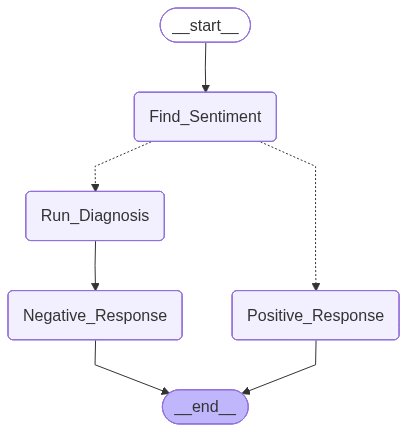

In [ ]:
workflow

In [ ]:
intial_state={
    'review': "I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality."
}
workflow.invoke(intial_state)

{'review': 'I’ve been trying to log in for over an hour now, and the app keeps freezing on the authentication screen. I even tried reinstalling it, but no luck. This kind of bug is unacceptable, especially when it affects basic functionality.',
 'sentiment': 'negative',
 'diagnosis': {'issue_type': 'Bug', 'tone': 'frustrated', 'urgency': 'high'},
 'response': 'Hi there,\n\nI’m really sorry you’re running into this issue—thank you for letting us know. I can understand how frustrating it must be, especially when it’s happening right now. Let’s get it resolved as quickly as possible.\n\n### Quick first‑step check\n1. **Refresh / restart** – Sometimes a simple page refresh or app restart clears the hiccup.  \n2. **Clear cache** – If you’re on a web browser, clear your cache and cookies, or if it’s a mobile app, clear the app cache (Settings → Apps → [Your App] → Storage → Clear Cache).  \n3. **Check the network** – Make sure your internet connection is stable. If you’re on Wi‑Fi, try switc